# Funciones de Agrupación y Agregado

# Función GroupBy()

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
s = pd.Series([10, 20, 30, 40, 50])

## Agrupar por otra list

In [6]:
ventas = pd.Series([100, 200, 150, 300, 250])
categorias = ['A', 'A', 'B', 'B', 'A']
ventas.groupby(categorias).sum()

A    550
B    450
dtype: int64

## Agrupar por indice

In [11]:
ventas = pd.Series(
    [100, 200, 150, 300],
    index=['Norte', 'Norte', 'Sur', 'Sur']
)

ventas.groupby(level=0).sum() # level = 0 indica que se agrupe por indice

Norte    300
Sur      450
dtype: int64

## Agrupar por los propios valores

In [13]:
s = pd.Series([1, 1, 2, 2, 2, 3])

s.groupby(s).count()

1    2
2    3
3    1
dtype: int64

**¿Qué devuelve groupby()?**

Devueve un objeto *SeriesGroupBy* este objeto no hace nada todavia, solo prepara los grupos.
La operación ocurre cuando aplicas:
- sum()
- mean()
- count()
- agg()
- apply()

# Función Agg()

Sirve para aplicar una o varias funciones de agregación a una Serie o a un **groupby**
- Si groupby() separa los datos en grupos
- Entonces agg() decide que calculos hacer en cada grupo

In [15]:
s = pd.Series([10, 20, 30, 40, 50])

s.agg(['sum', 'mean', 'min', 'max'])

sum     150.0
mean     30.0
min      10.0
max      50.0
dtype: float64

In [16]:
s.agg(['mean'])

mean    30.0
dtype: float64

### Caso 2 agg() después de groupby()

In [37]:
ventas = pd.Series([100, 200, 150, 300, 250])
categorias = ['A', 'A', 'B', 'B', 'A']

ventas.groupby(categorias).agg(['sum', 'mean', 'count'])

,sum,mean,count
A,550,183.333333,3
B,450,225.000000,2


In [38]:
df_egresos = pd.DataFrame({
    "Categorias": [
        "Gastos fijo", 
        "Gastos fijo", 
        "Gasto variable", 
        "Gasto variable", 
        "Gasto variable", 
        "Gastos fijo"],
    "Servicio/Producto": [
        "Servicio Luz", 
        "Servicio Agua", 
        "Compra material escritorio", 
        "Compra medidor", 
        "Compra material de limpieza", 
        "Servicio Agua"],
    "Precio": [
        2700.54,
        1566.26,
        230.12, 
        456, 
        250.44,
        200]
})
df_egresos

,Categorias,Servicio/Producto,Precio
0,Gastos fijo,Servicio Luz,2700.54
1,Gastos fijo,Servicio Agua,1566.26
2,Gasto variable,Compra material escritorio,230.12
3,Gasto variable,Compra medidor,456.00
4,Gasto variable,Compra material de limpieza,250.44
5,Gastos fijo,Servicio Agua,200.00


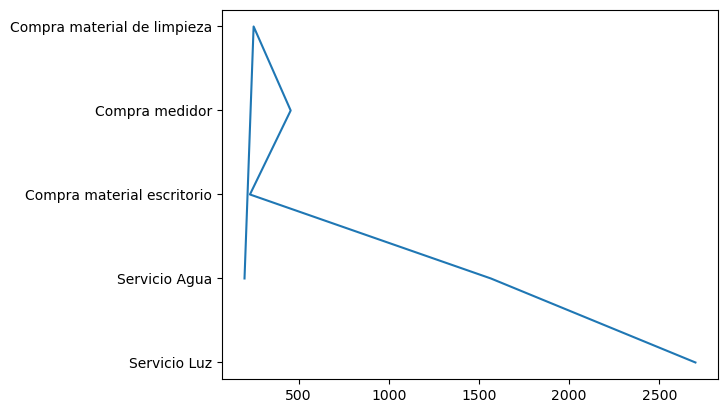

In [39]:
plt.plot(df_egresos["Precio"], df_egresos["Servicio/Producto"])

In [44]:
df_egresos_ = df_egresos.groupby(["Categorias", "Servicio/Producto"], as_index=False)["Precio"].sum()
df_egresos_["Total"] = df_egresos_["Precio"].sum()
df_egresos_

,Categorias,Servicio/Producto,Precio,Total
0,Gasto variable,Compra material de limpieza,250.44,5403.36
1,Gasto variable,Compra material escritorio,230.12,5403.36
2,Gasto variable,Compra medidor,456.00,5403.36
3,Gastos fijo,Servicio Agua,1766.26,5403.36
4,Gastos fijo,Servicio Luz,2700.54,5403.36


In [ ]:
df_egresos